# 01 — Accesibilidad al transporte

**La pregunta.** ¿Qué tan conectada está cada propiedad a la red de transporte de la
Ciudad, y el mercado lo paga en el precio?

**Por qué importa para el inversor.** Un inquilino paga todos los días la caminata
hasta la red. Si la accesibilidad se paga en el precio, la propiedad bien conectada
cuesta más y rinde distinto; si ya está incorporada en el precio del barrio, el
inversor no tiene que pagar una prima por estar cerca de una estación. Responde a
**H2** y alimenta **P2** (qué propiedad comprar).

**Qué cambia respecto de la 2da entrega.** H2 había quedado como "no evaluable":
faltaba la fusión espacial, y la devolución pidió no cerrarla con el subte solo,
porque no cubre el sur ni el oeste. Este notebook integra subte, tren y Metrobús.

**De dónde salen los números.** `src/espacial.py` construye las capas y las
distancias; `src/accesibilidad.py` estima la forma de H2. Este notebook lee sus
salidas y las recorre en orden. El contraste formal con p-valor va en el notebook 04.

1. Las capas · 2. Cobertura del dato · 3. La medida · 4. El nivel territorial ·
5. H2: magnitud y forma · 6. Lo que la medida no mide

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import accesibilidad as A
import eda
import espacial as E
import supuestos as S

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

P, X = "../data/processed", "../data/external"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
puntos = pd.read_csv(f"{X}/transporte_estaciones.csv", encoding="utf-8-sig")
verdes = pd.read_csv(f"{X}/espacios_verdes.csv", encoding="utf-8-sig")
print(f"Dataset: {len(df):,} avisos x {df.shape[1]} columnas")

Dataset: 12,097 avisos x 128 columnas


## 1. Las capas

Cuatro capas de Buenos Aires Data, bajadas de la fuente oficial con fecha y
versionadas en `data/external/`. Las de subte y tren son las mismas que usaba el
repositorio de trabajo del grupo; el Metrobús es nuevo en esta entrega.

In [2]:
capas = (puntos.groupby("capa", sort=False)
         .agg(puntos=("nombre", "size"), lineas=("linea", "nunique"), descarga=("fecha_descarga", "first")))
capas.loc["espacios verdes (poligonos)"] = [len(verdes), np.nan, verdes["fecha_descarga"].iloc[0]]
capas

,puntos,lineas,descarga
capa,,,
subte_bocas,379,6.0,2026-10-27
subte_estaciones,90,6.0,2026-10-27
tren,301,8.0,2026-10-27
metrobus,390,20.0,2026-10-27
espacios verdes (poligonos),608,NaN,2026-10-27


La capa de bocas de subte es de 2019. Antes de usarla hay que comprobar que cubra la
red actual: cada estación de la capa de 2024 tiene que tener una boca cerca.

In [3]:
bocas = puntos[puntos["capa"] == "subte_bocas"].reset_index(drop=True)
est = puntos[puntos["capa"] == "subte_estaciones"].rename(columns={"lat": "latitud", "lon": "longitud"})
d, _ = E.distancia_al_mas_cercano(est, bocas)
print(f"Estaciones vigentes: {len(est)}. Distancia a la boca mas cercana: "
      f"mediana {np.median(d):.0f} m, maxima {d.max():.0f} m.")

Estaciones vigentes: 90. Distancia a la boca mas cercana: mediana 20 m, maxima 91 m.


**Lectura.** Todas las estaciones vigentes tienen una boca a menos de 100 m: la capa
de 2019 cubre la red de hoy. Lo que **no** está en ninguna capa del portal es el
**Premetro**, que sirve a Villa Soldati y Villa Lugano. Es la primera limitación de
la medida, y pesa justo en el sur.

## 2. Cobertura del dato

La fusión es por coordenadas. Si los avisos sin coordenadas se concentraran en una
zona, la medida quedaría sesgada ahí. Se mide como **tasa** por comuna, no como
conteo: una comuna con mucha oferta junta más faltantes sin que su dato sea peor.

In [4]:
sin = df[["latitud", "longitud"]].isna().any(axis=1)
print(f"Avisos sin coordenadas: {int(sin.sum())} de {len(df):,} ({sin.mean():.2%})")
tasa = (sin.groupby(df["comuna"]).agg(["sum", "size", "mean"])
        .rename(columns={"sum": "sin_coord", "size": "avisos", "mean": "tasa"}))
tasa["tasa"] = tasa["tasa"] * 100
tasa[tasa["sin_coord"] > 0].sort_values("tasa", ascending=False)

Avisos sin coordenadas: 7 de 12,097 (0.06%)


,sin_coord,avisos,tasa
comuna,,,
8,1,198,0.5
10,2,618,0.3
14,4,1356,0.3


**Lectura.** Siete avisos sin coordenadas, en tres comunas, ninguna por encima del
0,51%. No se concentran en el sur: hay uno en Villa Lugano y cuatro en Palermo. Quedan
sin distancia (nulo, nunca cero) y no sesgan la medida.

## 3. La medida

> **`dist_transporte_m`: los metros, en línea recta, hasta la estación más cercana de
> cualquiera de las tres redes masivas (subte, tren o Metrobús).**

Es el mínimo de las tres distancias, sin pesos. Un índice ponderado exigiría pesar cada
modo por su frecuencia, y no hay un dato de frecuencia por estación: los pesos serían
inventados. Contar cuántos modos hay cerca confunde un conteo con una tasa. Las tres
distancias por modo quedan como columnas para medir qué agrega la combinación.

In [5]:
dist = ["dist_subte_m", "dist_tren_m", "dist_metrobus_m", "dist_transporte_m"]
resumen = df[dist].describe(percentiles=[.1, .25, .5, .75, .9]).T[["10%", "25%", "50%", "75%", "90%", "max"]]
resumen.index = ["subte", "tren", "metrobus", "combinada"]
display(resumen.round(0))
print((df["modo_cercano"].value_counts(normalize=True) * 100).round(1).to_string())

,10%,25%,50%,75%,90%,max
subte,166.0,300.0,580.0,"1,234.0","2,862.0","5,798.0"
tren,367.0,607.0,980.0,"1,421.0","1,766.0","2,872.0"
metrobus,197.0,445.0,966.0,"1,749.0","2,237.0","3,271.0"
combinada,113.0,206.0,363.0,596.0,842.0,"2,872.0"


modo_cercano
subte      48.2
metrobus   29.9
tren       22.0


### Gráfico 01 — ¿El subte solo describe la accesibilidad del sur y el oeste?

Porcentaje de los avisos de cada comuna con una estación a menos de 800 m (diez
minutos a pie, `supuestos.RADIO_CAMINATA_M`), con el subte solo y con las tres redes.

guardado: ../graficos\01_acceso_por_comuna.png


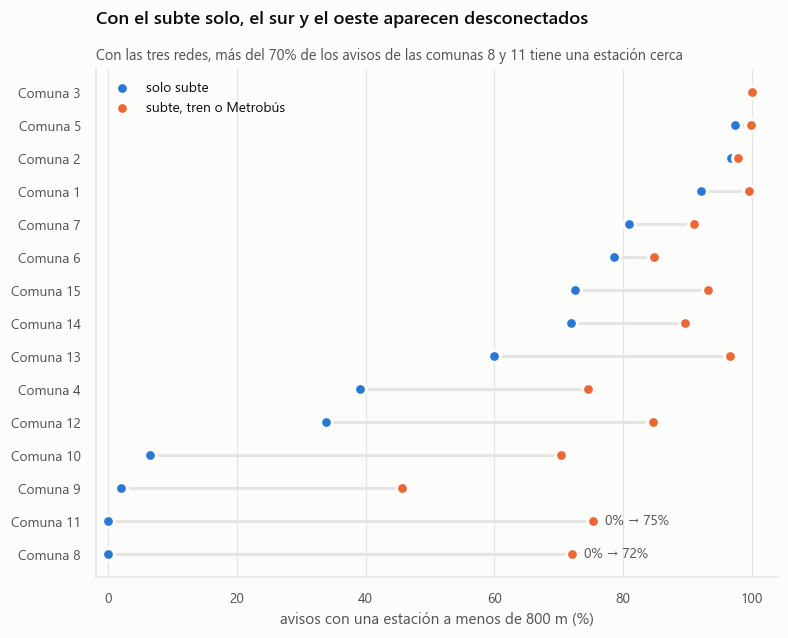

In [6]:
r = S.RADIO_CAMINATA_M
c = df[df["dist_transporte_m"].notna()]
t = c.groupby("comuna").agg(subte=("dist_subte_m", lambda s: (s <= r).mean() * 100),
                            combinada=("dist_transporte_m", lambda s: (s <= r).mean() * 100))
t = t.sort_values("subte")

fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(t))
ax.hlines(yy, t["subte"], t["combinada"], color=eda.GRILLA, linewidth=2, zorder=1)
ax.scatter(t["subte"], yy, s=60, color=eda.SERIE_1, label="solo subte", zorder=2,
           edgecolor=eda.SUPERFICIE, linewidth=2)
ax.scatter(t["combinada"], yy, s=60, color=eda.SERIE_2, label="subte, tren o Metrobús", zorder=3,
           edgecolor=eda.SUPERFICIE, linewidth=2)
ax.set_yticks(yy, [f"Comuna {k}" for k in t.index])
ax.set_xlim(-2, 104)
ax.set_xlabel(f"avisos con una estación a menos de {r} m (%)")
for k in (8, 11):
    i = list(t.index).index(k)
    ax.annotate(f"{t.loc[k, 'subte']:.0f}% → {t.loc[k, 'combinada']:.0f}%", (t.loc[k, "combinada"], i),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=eda.TINTA_2)
eda.sin_grilla_y(ax)
ax.legend(loc="upper left")
eda.titulo(ax, "Con el subte solo, el sur y el oeste aparecen desconectados",
           "Con las tres redes, más del 70% de los avisos de las comunas 8 y 11 tiene una estación cerca")
eda.guardar(fig, 1, "acceso_por_comuna")
plt.show()

**Lectura.** Es el punto de la devolución, medido. En las comunas 8 (sur) y 11
(oeste) ningún aviso tiene una boca de subte a menos de 800 m; con tren y Metrobús,
más del 70% tiene una estación a esa distancia. En toda la Ciudad, uno de cada cuatro
avisos (26%) queda dentro del radio con las tres redes y afuera con el subte solo. Cerrar H2 con
el subte solo habría medido la distancia a una red que esas comunas no tienen.

## 4. El nivel territorial

La medida es por aviso. La alternativa, un promedio por barrio, es más simple, pero
le asigna el mismo acceso a todos los avisos de un barrio.

### Gráfico 02 — ¿Alcanza con un promedio por barrio?

Para los barrios con al menos 30 avisos donde conviven avisos dentro y fuera de los
800 m: el rango entre el 10% más cercano y el 10% más lejano de la red.

Barrios con 30+ avisos: 44; con avisos dentro y fuera del radio: 20


guardado: ../graficos\02_heterogeneidad_barrio.png


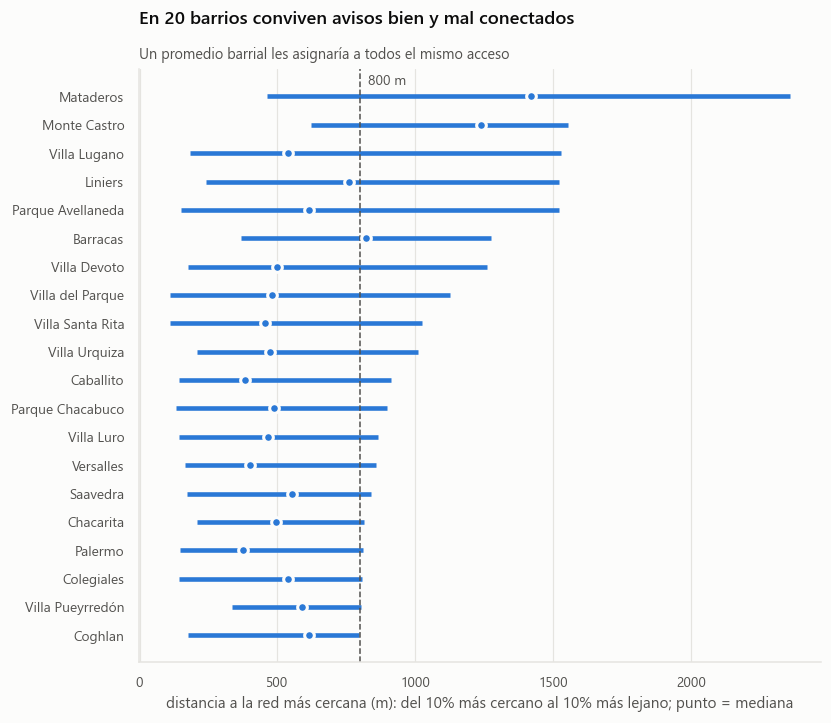

In [7]:
g = c.groupby("barrio")["dist_transporte_m"]
h = pd.DataFrame({"avisos": g.size(), "p10": g.quantile(.1), "mediana": g.median(), "p90": g.quantile(.9),
                  "dentro": g.apply(lambda s: (s <= r).mean() * 100)})
h = h[h["avisos"] >= S.MIN_VENTAS_BARRIO]
mixtos = h[h["dentro"].between(10, 90)].sort_values("p90")
print(f"Barrios con {S.MIN_VENTAS_BARRIO}+ avisos: {len(h)}; con avisos dentro y fuera del radio: {len(mixtos)}")

fig, ax = plt.subplots(figsize=(8, 7))
yy = np.arange(len(mixtos))
ax.hlines(yy, mixtos["p10"], mixtos["p90"], color=eda.SERIE_1, linewidth=3)
ax.scatter(mixtos["mediana"], yy, s=40, color=eda.SERIE_1, edgecolor=eda.SUPERFICIE, linewidth=2, zorder=3)
ax.axvline(r, color=eda.TINTA_2, linewidth=1, linestyle="--")
ax.text(r + 30, len(mixtos) - 0.6, f"{r} m", color=eda.TINTA_2, fontsize=9)
ax.set_yticks(yy, eda.nombres_barrio(mixtos.index))
ax.set_xlabel("distancia a la red más cercana (m): del 10% más cercano al 10% más lejano; punto = mediana")
eda.sin_grilla_y(ax)
eda.titulo(ax, f"En {len(mixtos)} barrios conviven avisos bien y mal conectados",
           "Un promedio barrial les asignaría a todos el mismo acceso")
eda.guardar(fig, 2, "heterogeneidad_barrio")
plt.show()

**Lectura.** En casi la mitad de los barrios con oferta suficiente conviven avisos
bien y mal conectados. En Mataderos, el 10%
más cercano está a menos de 500 m de una estación y el 10% más lejano, a más de 2 km.
Por eso la medida se calcula por aviso y los resúmenes por zona se hacen por comuna,
como tasas.

## 5. H2: magnitud y forma

> **H2.** El precio del m² decrece con la distancia al transporte, y existe un radio
> de influencia a partir del cual el beneficio se diluye.

El método está declarado desde la 1ra entrega: regresión de log(USD/m²) sobre la
distancia **con efectos fijos de barrio**. Sin el barrio, la distancia mide
centralidad: los barrios caros están cerca de todo. Con el barrio fijo, se comparan
avisos del mismo barrio más cerca o más lejos de una estación.

In [8]:
v = df[(df["operacion"] == "venta") & df["venta_m2_usd"].notna() & df["dist_transporte_m"].notna()].copy()
v["y"] = np.log(v["venta_m2_usd"])
fe = A.matriz_base(v, controles=False)
_, r2_fe = A.ols(fe, v["y"].values)
filas = []
for col, nombre in A.MEDIDAS.items():
    km = v[[col]].values / 1000
    b0, _ = A.ols(np.hstack([np.ones((len(v), 1)), km]), v["y"].values)
    b1, r2 = A.ols(np.hstack([fe, km]), v["y"].values)
    filas.append({"medida": nombre, "sin barrio (%/km)": A.efecto_pct(b0[-1]),
                  "con barrio (%/km)": A.efecto_pct(b1[-1]), "R2 que agrega": round(r2 - r2_fe, 4)})
print(f"Ventas: {len(v):,}. R2 del barrio solo: {r2_fe:.3f}")
t = pd.DataFrame(filas).set_index("medida")
t["R2 que agrega"] = t["R2 que agrega"].map("{:.4f}".format)
t

Ventas: 10,743. R2 del barrio solo: 0.422


,sin barrio (%/km),con barrio (%/km),R2 que agrega
medida,,,
combinada,-12.9,-6.2,0.0018
subte,-7.4,-3.4,0.0013
tren,-14.2,-4.7,0.0019
metrobus,1.9,-3.1,0.0014


**Lectura.** Sin el barrio, cada kilómetro hasta la red resta cerca de 13% al m². Con
el barrio fijo, la pendiente se reduce a la mitad y la distancia agrega dos milésimas
de R² a un modelo donde el barrio solo explica 0,42. La mayor parte de lo que parecía
accesibilidad era centralidad.

Una pendiente lineal promedia toda la distancia. La pregunta del radio de influencia
es de forma: ¿la penalidad es pareja, o aparece a partir de cierta distancia?

### Gráfico 03 — ¿Cuánto vale menos el m² a medida que se aleja la red, comparando dentro del barrio?

Efecto sobre el precio del m² contra los avisos a menos de 300 m de la red, con tres
especificaciones. Los controles (tipo, superficie, antigüedad, a reciclar, amenities,
cochera) importan porque lejos de la red hay más casas y PH.

guardado: ../graficos\03_h2_perfil_distancia.png


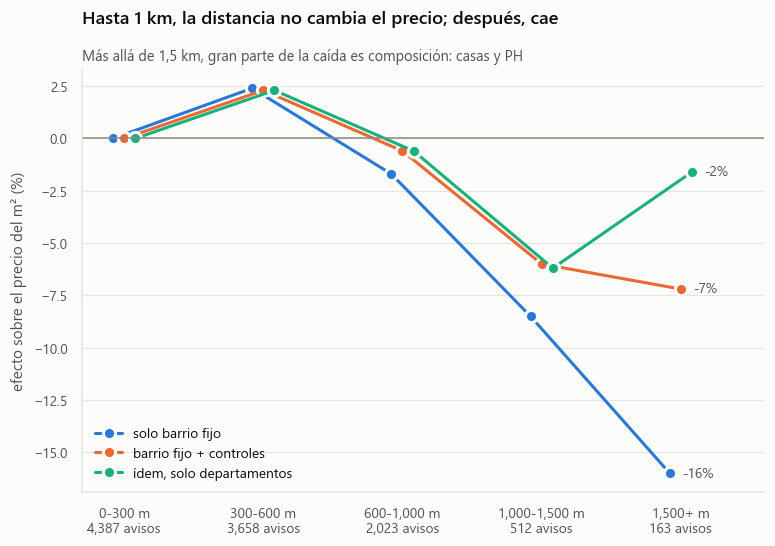

In [9]:
perfil = pd.read_csv(f"{P}/h2_perfil_distancia.csv", encoding="utf-8-sig")
orden = list(A.tramos(pd.Series([0])).cat.categories)
comb = perfil[perfil["medida"] == "combinada"]
esp = {"barrio": ("solo barrio fijo", eda.SERIE_1),
       "barrio + controles": ("barrio fijo + controles", eda.SERIE_2),
       "barrio + controles, deptos": ("ídem, solo departamentos", eda.SERIE_3)}

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(orden))
# Corrimiento horizontal chico: las dos especificaciones con controles casi
# coinciden hasta 1,5 km y una taparia a la otra.
for k, (clave, (etiqueta, color)) in enumerate(esp.items()):
    s = comb[comb["especificacion"] == clave].set_index("tramo_m").loc[orden, "efecto_pct"]
    xx = x + (k - 1) * 0.08
    ax.plot(xx, s.values, marker="o", color=color, label=etiqueta,
            markeredgecolor=eda.SUPERFICIE, markeredgewidth=2)
    ax.annotate(f"{s.values[-1]:+.0f}%", (xx[-1], s.values[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=eda.TINTA_2)
n = comb[comb["especificacion"] == "barrio"].set_index("tramo_m").loc[orden, "n"]
ax.set_xticks(x, [f"{t} m\n{k:,} avisos" for t, k in zip(orden, n)])
ax.axhline(0, color=eda.TINTA_3, linewidth=1)
ax.set_ylabel("efecto sobre el precio del m² (%)")
ax.set_xlim(-0.3, len(orden) - 0.4)
ax.legend(loc="lower left")
eda.titulo(ax, "Hasta 1 km, la distancia no cambia el precio; después, cae",
           "Más allá de 1,5 km, gran parte de la caída es composición: casas y PH")
eda.guardar(fig, 3, "h2_perfil_distancia")
plt.show()

**Lectura.** Hasta 1 km el perfil es plano: entre 300 y 1.000 m de la red, el m² vale
lo mismo que al lado de una estación, con diferencias de menos de 3%. Entre 1 y 1,5 km cae 6%, con y sin casas y PH.
Más allá de 1,5 km el tramo es chico (163 avisos) y la caída depende de qué se mire:
−16% sin controles, −7% con controles, −2% solo en departamentos. Ese tramo está
dominado por casas y PH, que tienen otro precio del m² por razones que no son la
distancia.

In [10]:
radio = []
X0 = A.matriz_base(v, controles=True)
for u in S.UMBRALES_H2_M:
    q = np.maximum(v["dist_transporte_m"].values - u, 0)[:, None] / 1000
    b, r2 = A.ols(np.hstack([X0, q]), v["y"].values)
    radio.append({"umbral (m)": u, "% por km más allá": A.efecto_pct(b[-1]), "R2": r2})
t = pd.DataFrame(radio).set_index("umbral (m)")
t["R2"] = t["R2"].map("{:.5f}".format)
t

,% por km más allá,R2
umbral (m),,
400,-6.1,0.71292
600,-8.1,0.71296
800,-8.2,0.71252
1000,-6.8,0.71214
1200,-3.8,0.71194
1500,7.5,0.71196


**El radio de influencia.** Un modelo con quiebre (la distancia solo resta más allá
de un umbral) ajusta mejor con un umbral de 600 m, casi igual que con 400 m, pero la
diferencia de R² entre el mejor y el peor umbral es de una milésima: el quiebre no está
marcado con precisión. Junto con el perfil por tramos, que se mantiene plano hasta 1 km,
ubica el radio entre 600 m y 1 km: un rango, no un número.

In [11]:
por_modo = (perfil[perfil["especificacion"] == "barrio + controles"]
            .pivot(index="medida", columns="tramo_m", values="efecto_pct")[orden])
display(por_modo.loc[["subte", "tren", "metrobus", "combinada"]])

v["yd"] = v["y"] - v.groupby("barrio")["y"].transform("mean")
for lejos, g in v.groupby(v["dist_subte_m"] > 1000):
    print(f"subte {'a mas de 1 km' if lejos else 'hasta 1 km':<14} {len(g):>6,} avisos   "
          f"Spearman intra-barrio {g['yd'].corr(g['dist_subte_m'], method='spearman'):+.3f}")

tramo_m,0-300,300-600,"600-1,000","1,000-1,500","1,500+"
medida,,,,,
subte,0.0,2.1,0.3,-1.5,-6.1
tren,0.0,3.7,3.8,3.1,-0.9
metrobus,0.0,1.4,2.0,1.6,-1.3
combinada,0.0,2.3,-0.6,-6.0,-7.2


subte hasta 1 km      7,368 avisos   Spearman intra-barrio +0.058
subte a mas de 1 km   3,375 avisos   Spearman intra-barrio -0.000


**Por modo.** Con controles, la penalidad viene del subte (−6% a más de 1,5 km). Ni el
tren ni el Metrobús penalizan la lejanía: estar a 300-1.500 m del tren no vale menos
que estar al lado.

**El antecedente no se replica.** En el repositorio de trabajo había aparecido una
correlación intra-barrio negativa con la distancia al subte a más de 1 km. Con estos
datos, el Spearman en esos 3.375 avisos es cero.

**Lectura de H2.** La primera mitad del enunciado propuesto se sostiene: *la
accesibilidad ya está incorporada en el precio del barrio*. La segunda se sostiene con
una precisión: *salvo donde el transporte escasea*, entendido como el aviso y no el
barrio. El 6% de los avisos a más de 1 km de las tres redes cotiza alrededor de 6%
menos que sus comparables del mismo barrio.

## 6. Lo que la medida no mide

Una distancia en línea recta **no es accesibilidad real**:

- **No ve barreras.** Un aviso a 400 m de una estación en línea recta puede estar a
  1.500 m caminando si en el medio hay vías, una autopista o el Riachuelo.
- **No ve la frecuencia.** Una estación de tren con un tren por hora no equivale a un
  subte cada cuatro minutos, y en la medida valen lo mismo.
- **No ve el destino.** Estar cerca de una estación no dice adónde se llega.
- **Le falta el Premetro**, así que en el sur exagera la distancia a la red.

Es una cota inferior del esfuerzo de llegar a la red, no una medida de qué tan bien
conectado está un inmueble.

## Resumen del notebook

1. **El subte solo no describe la accesibilidad de CABA.** En las comunas 8 y 11 ningún
   aviso tiene subte a 800 m; con tren y Metrobús, más del 70% tiene una estación.
2. **La medida es por aviso.** En casi la mitad de los barrios un promedio barrial
   escondería avisos bien y mal conectados.
3. **H2, forma:** con el barrio fijo, la distancia casi no explica el precio. Hasta
   1 km no hay penalidad; entre 1 y 1,5 km el m² vale 6% menos. Radio de influencia:
   entre 600 y 1.000 m.
4. **Para el inversor (P2):** no hace falta pagar una prima por estar cerca de una
   estación dentro del barrio. El descuento lejos de la red es chico y está concentrado
   en el 6% de los avisos.

**Lo que este notebook no hace:** el contraste con p-valor de H2 (notebook 04) ni la
revisión del modelo de alquiler con estas variables (notebook 03).